# Derivación automática de tickets de soporte

Vicente Troncoso y Diego Silva · Desarrollo de Soluciones Inteligentes (02DSI243061) · EVAL-01

Los tickets llegan mezclados y alguien tiene que leerlos para decidir a qué área van. Este prototipo lee el texto de un ticket y sugiere la categoría que debe atenderlo. Si no está seguro, no deriva y lo deja para que lo revise una persona.

Para ejecutarlo, vaya a Entorno de ejecución y elija Ejecutar todo. Cuando la celda de datos lo pida, suba el archivo CSV de Bitext.

Datos: Bitext Customer Support Training Dataset, de Hugging Face (bitext/Bitext-customer-support-llm-chatbot-training-dataset), licencia cdla-sharing-1.0. Son tickets generados, no consultas reales, y están en inglés.

In [1]:
import hashlib
import json
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


## 1. Datos

In [2]:
RUTA = "Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv"

if not os.path.exists(RUTA):
    from google.colab import files
    RUTA = next(iter(files.upload()))

datos = pd.read_csv(RUTA)[["instruction", "category"]].rename(columns={"instruction": "texto", "category": "categoria"})
datos["texto"] = datos["texto"].str.strip()

print(datos.shape, "| textos únicos:", datos["texto"].nunique(), "| nulos:", int(datos.isna().sum().sum()))
print("Largo del texto (caracteres): mínimo", datos["texto"].str.len().min(), "| máximo", datos["texto"].str.len().max())
print(datos["categoria"].value_counts().to_string())
datos.sample(5, random_state=1)

Saving Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv to Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv
(26872, 2) | textos únicos: 24635 | nulos: 0
Largo del texto (caracteres): mínimo 6 | máximo 92
categoria
ACCOUNT         5986
ORDER           3988
REFUND          2992
CONTACT         1999
INVOICE         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950


,texto,categoria
4476,how can I check bill #12588?,INVOICE
676,I'm rtying to cancel order {{Order Number}},ORDER
16877,I do not know what to do to demand my money back,REFUND
26429,assistance to see if there are any news on the...,REFUND
22508,I don't know how t leave an opinion about a pr...,FEEDBACK


Hay textos repetidos. Si un mismo texto quedara en entrenamiento y en prueba, las métricas saldrían infladas, así que la partición mantiene juntos los textos idénticos.

In [3]:
CATEGORIAS = sorted(datos["categoria"].unique())
grupos = datos["texto"].factorize()[0]

corte = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
i_ent, i_pru = next(corte.split(datos, datos["categoria"], grupos))
ent, pru = datos.iloc[i_ent], datos.iloc[i_pru]

print("Entrenamiento:", len(ent), "| prueba:", len(pru))
print("Textos de prueba que también están en entrenamiento:", int(pru["texto"].isin(set(ent["texto"])).sum()))
pd.DataFrame({"entrenamiento %": (ent["categoria"].value_counts(normalize=True) * 100).round(1),
              "prueba %": (pru["categoria"].value_counts(normalize=True) * 100).round(1)})

Entrenamiento: 20143 | prueba: 6729
Textos de prueba que también están en entrenamiento: 0


,entrenamiento %,prueba %
categoria,,
ACCOUNT,22.3,22.2
CANCEL,3.5,3.6
CONTACT,7.4,7.4
DELIVERY,7.6,6.9
FEEDBACK,7.3,7.7
INVOICE,7.3,7.8
ORDER,14.9,14.5
PAYMENT,7.5,7.3
REFUND,11.0,11.5


## 2. Elección de la técnica

Se comparan tres técnicas sobre TF-IDF contra una línea base que siempre responde la categoría más frecuente. La comparación usa validación cruzada de 5 pliegues solo sobre el conjunto de entrenamiento, para no tocar la prueba.

In [4]:
def vectorizador():
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True, min_df=2)


candidatas = {
    "Clase mayoritaria (línea base)": Pipeline([("t", vectorizador()), ("c", DummyClassifier(strategy="most_frequent"))]),
    "TF-IDF + Naive Bayes": Pipeline([("t", vectorizador()), ("c", MultinomialNB())]),
    "TF-IDF + SVM lineal": Pipeline([("t", vectorizador()), ("c", LinearSVC())]),
    "TF-IDF + Regresión logística": Pipeline([("t", vectorizador()), ("c", LogisticRegression(max_iter=2000))]),
}
g_ent = grupos[i_ent]

filas = []
for nombre, pipe in candidatas.items():
    acc, f1 = [], []
    for a, b in GroupKFold(n_splits=5).split(ent["texto"], ent["categoria"], g_ent):
        m = clone(pipe).fit(ent["texto"].iloc[a], ent["categoria"].iloc[a])
        p = m.predict(ent["texto"].iloc[b])
        acc.append(accuracy_score(ent["categoria"].iloc[b], p))
        f1.append(f1_score(ent["categoria"].iloc[b], p, average="macro"))
    filas.append({"técnica": nombre, "exactitud": round(np.mean(acc), 3), "desv.": round(np.std(acc), 3), "F1 macro": round(np.mean(f1), 3)})
pd.DataFrame(filas)

,técnica,exactitud,desv.,F1 macro
0,Clase mayoritaria (línea base),0.223,0.004,0.033
1,TF-IDF + Naive Bayes,0.996,0.001,0.996
2,TF-IDF + SVM lineal,0.998,0.001,0.999
3,TF-IDF + Regresión logística,0.997,0.001,0.997


La regresión logística entrega una probabilidad por categoría, que es lo que necesita la regla de confianza. Se entrena con todo el conjunto de entrenamiento y se mide una sola vez sobre la prueba.

Exactitud: 0.997
F1 macro:  0.998

              precision    recall  f1-score   support

     ACCOUNT      0.993     1.000     0.996      1493
      CANCEL      1.000     1.000     1.000       243
     CONTACT      1.000     0.998     0.999       501
    DELIVERY      0.998     1.000     0.999       467
    FEEDBACK      1.000     0.998     0.999       520
     INVOICE      1.000     1.000     1.000       527
       ORDER      1.000     0.994     0.997       978
     PAYMENT      1.000     0.992     0.996       488
      REFUND      0.997     0.999     0.998       775
    SHIPPING      0.992     0.994     0.993       496
SUBSCRIPTION      1.000     0.992     0.996       241

    accuracy                          0.997      6729
   macro avg      0.998     0.997     0.998      6729
weighted avg      0.997     0.997     0.997      6729



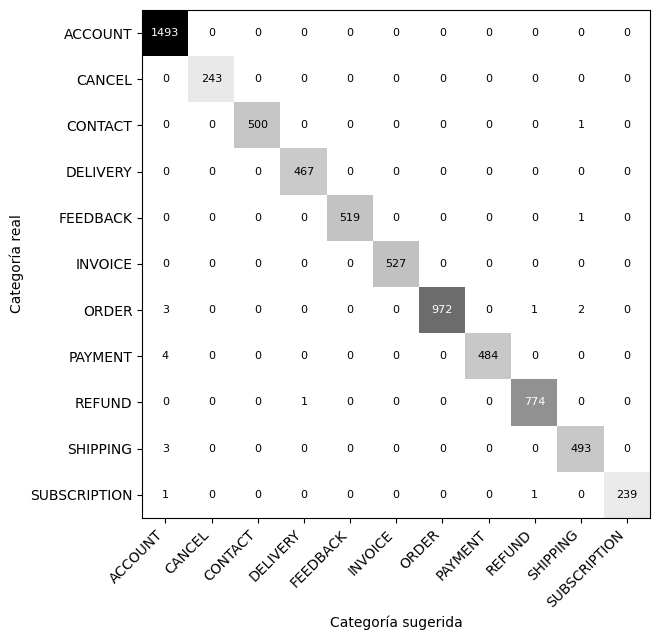

In [5]:
modelo = Pipeline([("tfidf", vectorizador()), ("clf", LogisticRegression(max_iter=2000))])
modelo.fit(ent["texto"], ent["categoria"])

pred = modelo.predict(pru["texto"])
print(f"Exactitud: {accuracy_score(pru['categoria'], pred):.3f}")
print(f"F1 macro:  {f1_score(pru['categoria'], pred, average='macro'):.3f}\n")
print(classification_report(pru["categoria"], pred, digits=3))

cm = confusion_matrix(pru["categoria"], pred, labels=CATEGORIAS)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.imshow(cm, cmap="Greys")
ax.set_xticks(range(len(CATEGORIAS)))
ax.set_yticks(range(len(CATEGORIAS)))
ax.set_xticklabels(CATEGORIAS, rotation=45, ha="right")
ax.set_yticklabels(CATEGORIAS)
for i in range(len(CATEGORIAS)):
    for j in range(len(CATEGORIAS)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
ax.set_xlabel("Categoría sugerida")
ax.set_ylabel("Categoría real")
plt.tight_layout()
plt.show()

## 3. Umbral de confianza

Si la probabilidad más alta es menor que el umbral, el ticket pasa a revisión manual. Subir el umbral automatiza menos, pero con más aciertos.

In [6]:
proba = modelo.predict_proba(pru["texto"])
confianza = proba.max(axis=1)
sugerida = modelo.classes_[proba.argmax(axis=1)]
acierto = sugerida == pru["categoria"].values

filas = []
for u in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    auto = confianza >= u
    filas.append({
        "umbral": u,
        "% derivados solos": round(100 * auto.mean(), 1),
        "% correctos entre los derivados": round(100 * acierto[auto].mean(), 1),
        "% a revisión manual": round(100 * (~auto).mean(), 1),
    })
pd.DataFrame(filas)

,umbral,% derivados solos,% correctos entre los derivados,% a revisión manual
0,0.0,100.0,99.7,0.0
1,0.4,99.6,99.9,0.4
2,0.5,99.1,99.9,0.9
3,0.6,98.2,100.0,1.8
4,0.7,97.1,100.0,2.9
5,0.8,93.6,100.0,6.4
6,0.9,83.2,100.0,16.8


In [17]:
UMBRAL = 0.6

joblib.dump({"modelo": modelo, "umbral": UMBRAL}, "modelo_tickets.joblib")
paquete = joblib.load("modelo_tickets.joblib")
modelo = paquete["modelo"]
UMBRAL = paquete["umbral"]
print("Modelo cargado desde archivo. Umbral:", UMBRAL)

Modelo cargado desde archivo. Umbral: 0.6


## 4. Aplicación

El ticket es un diccionario con un campo, `texto`, de 5 a 500 caracteres. Si algo incumple esa regla, se informan todos los errores y el modelo no se ejecuta. Una advertencia deja pasar el ticket pero avisa que el resultado puede no ser confiable: cuando el texto tiene menos de 50 % de letras o ninguna de sus palabras está en el vocabulario del modelo. El 50 % es un criterio del equipo, sin calibrar con datos reales.

In [11]:
class TicketInvalido(Exception):
    def __init__(self, errores):
        self.errores = errores
        super().__init__("; ".join(errores))


llamadas_al_modelo = 0


def validar_ticket(ticket):
    errores, advertencias = [], []
    if not isinstance(ticket, dict):
        return ["El ticket debe ser un diccionario con el campo 'texto'."], []
    for campo in ticket:
        if campo != "texto":
            errores.append(f"El campo '{campo}' no existe en el contrato.")

    texto = ticket.get("texto")
    if texto is None:
        errores.append("Falta el campo obligatorio 'texto'.")
    elif not isinstance(texto, str):
        errores.append(f"'texto' debe ser texto y recibí {type(texto).__name__}.")
    else:
        limpio = texto.strip()
        n = len(limpio)
        if n < 5:
            errores.append(f"'texto' es demasiado corto ({n} caracteres); se necesitan al menos 5.")
        elif n > 500:
            errores.append(f"'texto' es demasiado largo ({n} caracteres); el máximo es 500.")
        else:
            if sum(ch.isalpha() for ch in limpio) / n < 0.5:
                advertencias.append("El texto tiene pocas letras; la sugerencia puede no ser confiable.")
            tfidf = modelo.named_steps["tfidf"]
            if not any(t in tfidf.vocabulary_ for t in tfidf.build_analyzer()(limpio)):
                advertencias.append("Ninguna palabra del texto es conocida por el modelo; la sugerencia es poco confiable.")
    return errores, advertencias


def clasificar_ticket(ticket):
    global llamadas_al_modelo
    errores, advertencias = validar_ticket(ticket)
    if errores:
        raise TicketInvalido(errores)
    llamadas_al_modelo += 1
    p = modelo.predict_proba([ticket["texto"]])[0]
    probs = {a: float(x) for a, x in zip(modelo.classes_, p)}
    categoria = max(probs, key=probs.get)
    conf = probs[categoria]
    if conf >= UMBRAL:
        decision = "derivar"
        mensaje = f"Se sugiere derivar a {categoria} ({conf * 100:.0f} % de confianza)."
    else:
        decision = "revisar a mano"
        mensaje = (f"La confianza es baja ({conf * 100:.0f} %); la mejor opción parece {categoria}, "
                   "pero conviene que la revise una persona antes de derivar.")
    return {"categoria_sugerida": categoria, "confianza": round(conf, 4), "decision": decision,
            "advertencias": advertencias, "mensaje": mensaje}


def mostrar(r):
    print(json.dumps(r, indent=2, ensure_ascii=False))


def huella_modelo():
    clf, tfidf = modelo.named_steps["clf"], modelo.named_steps["tfidf"]
    b = clf.coef_.tobytes() + clf.intercept_.tobytes() + tfidf.idf_.tobytes()
    return hashlib.sha256(b).hexdigest()[:16]


HUELLA_INICIAL = huella_modelo()

## 5. Demostración

Un ticket claro:

In [18]:
claro = {"texto": "How do I change my shipping address?"}
print("ENTRADA:", json.dumps(claro, ensure_ascii=False))
mostrar(clasificar_ticket(claro))

ENTRADA: {"texto": "How do I change my shipping address?"}
{
  "categoria_sugerida": "SHIPPING",
  "confianza": 0.9855,
  "decision": "derivar",
  "advertencias": [],
  "mensaje": "Se sugiere derivar a SHIPPING (99 % de confianza)."
}


Un ticket ambiguo:

In [19]:
ambiguo = {"texto": "I need help with my order and my payment"}
print("ENTRADA:", json.dumps(ambiguo, ensure_ascii=False))
mostrar(clasificar_ticket(ambiguo))

ENTRADA: {"texto": "I need help with my order and my payment"}
{
  "categoria_sugerida": "PAYMENT",
  "confianza": 0.5386,
  "decision": "revisar a mano",
  "advertencias": [],
  "mensaje": "La confianza es baja (54 %); la mejor opción parece PAYMENT, pero conviene que la revise una persona antes de derivar."
}


Entradas inválidas, rechazadas antes de llegar al modelo:

In [20]:
invalidos = {
    "texto vacío": {"texto": "   "},
    "falta el texto": {},
    "texto que no es texto": {"texto": 12345},
    "campo que no existe": {"texto": "I want to cancel my subscription", "rut": "x"},
    "texto demasiado largo": {"texto": "help " * 120},
}
antes = llamadas_al_modelo
for nombre, entrada in invalidos.items():
    try:
        clasificar_ticket(entrada)
    except TicketInvalido as e:
        print(f"[{nombre}]")
        for m in e.errores:
            print(" -", m)
print("\nLlamadas al modelo durante estos casos:", llamadas_al_modelo - antes)

[texto vacío]
 - 'texto' es demasiado corto (0 caracteres); se necesitan al menos 5.
[falta el texto]
 - Falta el campo obligatorio 'texto'.
[texto que no es texto]
 - 'texto' debe ser texto y recibí int.
[campo que no existe]
 - El campo 'rut' no existe en el contrato.
[texto demasiado largo]
 - 'texto' es demasiado largo (599 caracteres); el máximo es 500.

Llamadas al modelo durante estos casos: 0


Un texto sin palabras, que se procesa pero con advertencias:

In [21]:
mostrar(clasificar_ticket({"texto": "?????? 12345 !!!! ...."}))

{
  "categoria_sugerida": "ACCOUNT",
  "confianza": 0.2837,
  "decision": "revisar a mano",
  "advertencias": [
    "El texto tiene pocas letras; la sugerencia puede no ser confiable.",
    "Ninguna palabra del texto es conocida por el modelo; la sugerencia es poco confiable."
  ],
  "mensaje": "La confianza es baja (28 %); la mejor opción parece ACCOUNT, pero conviene que la revise una persona antes de derivar."
}


## 6. Validación

Errores del modelo sobre la prueba: qué categorías confunde y con qué confianza.

In [22]:
errores = pru.assign(sugerida=sugerida, confianza=confianza)[~acierto]
print(f"Errores: {len(errores)} de {len(pru)}")
print(f"Confianza media de un error: {errores['confianza'].mean():.3f} | de un acierto: {confianza[acierto].mean():.3f}")
print(f"Errores con confianza de {UMBRAL} o más (se derivarían mal): {(errores['confianza'] >= UMBRAL).sum()}")
print()
print(pd.crosstab(errores["categoria"], errores["sugerida"]).to_string())
errores.sort_values("confianza", ascending=False)[["texto", "categoria", "sugerida", "confianza"]].head(15)

Errores: 18 de 6729
Confianza media de un error: 0.429 | de un acierto: 0.938
Errores con confianza de 0.6 o más (se derivarían mal): 2

sugerida      ACCOUNT  DELIVERY  REFUND  SHIPPING
categoria                                        
CONTACT             0         0       0         1
FEEDBACK            0         0       0         1
ORDER               3         0       1         2
PAYMENT             4         0       0         0
REFUND              0         1       0         0
SHIPPING            3         0       0         0
SUBSCRIPTION        1         0       1         0


,texto,categoria,sugerida,confianza
23556,deliveryaddress issue,SHIPPING,ACCOUNT,0.682249
18014,need to report an issue with paymentr,PAYMENT,ACCOUNT,0.679978
18276,i do not know what to do to report an issue wi...,PAYMENT,ACCOUNT,0.594725
25056,i want help to track purchase00123842,ORDER,REFUND,0.589484
15925,when can I expect a refund,REFUND,DELIVERY,0.561879
8440,ucstomer service mail address,CONTACT,SHIPPING,0.497321
22017,ya have an address to submit some feednack,FEEDBACK,SHIPPING,0.487044
18145,where can i report errors with onlinepayment,PAYMENT,ACCOUNT,0.482526
18864,solve problems with apyment,PAYMENT,ACCOUNT,0.438680
2256,is it possible to edit the bloody deliveryaddress,SHIPPING,ACCOUNT,0.365073


Casos límite:

In [23]:
casos = {
    "todo en minúsculas": "i want to cancel my subscription",
    "todo en mayúsculas": "I WANT TO TRACK MY ORDER",
    "con errores de tipeo": "i cant recieve my refnd for the ordr",
    "dos temas en uno": "I want to cancel my order and get a refund",
    "fuera de dominio": "what is the best recipe for tomato soup",
    "en español": "quiero cancelar mi pedido y recibir un reembolso",
    "una sola palabra": "invoice",
    "muy ambiguo": "I need help with something",
    "solo símbolos": "?????? 12345 !!!! ....",
}
filas = []
for nombre, texto in casos.items():
    r = clasificar_ticket({"texto": texto})
    filas.append({"caso": nombre, "categoría sugerida": r["categoria_sugerida"], "confianza": r["confianza"], "decisión": r["decision"]})
pd.DataFrame(filas)

,caso,categoría sugerida,confianza,decisión
0,todo en minúsculas,SUBSCRIPTION,0.4965,revisar a mano
1,todo en mayúsculas,REFUND,0.4286,revisar a mano
2,con errores de tipeo,ACCOUNT,0.3458,revisar a mano
3,dos temas en uno,REFUND,0.3937,revisar a mano
4,fuera de dominio,DELIVERY,0.2605,revisar a mano
5,en español,ACCOUNT,0.2837,revisar a mano
6,una sola palabra,INVOICE,0.9888,derivar
7,muy ambiguo,ORDER,0.4537,revisar a mano
8,solo símbolos,ACCOUNT,0.2837,revisar a mano


Tickets escritos a mano, con frases que no siguen las plantillas del dataset, y la categoría que esperaba una persona:

In [24]:
manuales = [
    ("I was charged twice for my last invoice and I need a refund", "REFUND"),
    ("I want to cancel my subscription", "CANCEL"),
    ("How can I track my order?", "ORDER"),
    ("My package has not arrived yet", "DELIVERY"),
    ("I forgot my password and cannot log in", "ACCOUNT"),
    ("Where can I find my invoice from last month?", "INVOICE"),
    ("I would like to speak with a human agent", "CONTACT"),
    ("How do I change my shipping address?", "SHIPPING"),
    ("The payment did not go through", "PAYMENT"),
    ("I want to leave a complaint about your service", "FEEDBACK"),
    ("Can I get my money back for this product?", "REFUND"),
    ("I need to change the delivery address of my order", "SHIPPING"),
    ("how do i unsubscribe from the newsletter", "SUBSCRIPTION"),
    ("my card was declined when i tried to pay", "PAYMENT"),
    ("I want to create an account", "ACCOUNT"),
    ("I need to cancel my order", "ORDER"),
]
filas = []
for texto, esperada in manuales:
    r = clasificar_ticket({"texto": texto})
    filas.append({"ticket": texto, "esperada": esperada, "sugerida": r["categoria_sugerida"], "confianza": r["confianza"], "decisión": r["decision"]})
tabla = pd.DataFrame(filas)
derivados = tabla[tabla["decisión"] == "derivar"]
print(f"Derivados solos: {len(derivados)} de {len(tabla)} | correctos entre ellos: {(derivados['esperada'] == derivados['sugerida']).sum()} de {len(derivados)}")
print(f"Sugerencia correcta en total: {(tabla['esperada'] == tabla['sugerida']).sum()} de {len(tabla)}")
tabla

Derivados solos: 10 de 16 | correctos entre ellos: 10 de 10
Sugerencia correcta en total: 12 de 16


,ticket,esperada,sugerida,confianza,decisión
0,I was charged twice for my last invoice and I ...,REFUND,INVOICE,0.4377,revisar a mano
1,I want to cancel my subscription,CANCEL,SUBSCRIPTION,0.4965,revisar a mano
2,How can I track my order?,ORDER,REFUND,0.3044,revisar a mano
3,My package has not arrived yet,DELIVERY,ACCOUNT,0.4289,revisar a mano
4,I forgot my password and cannot log in,ACCOUNT,ACCOUNT,0.6407,derivar
5,Where can I find my invoice from last month?,INVOICE,INVOICE,0.8948,derivar
6,I would like to speak with a human agent,CONTACT,CONTACT,0.9741,derivar
7,How do I change my shipping address?,SHIPPING,SHIPPING,0.9855,derivar
8,The payment did not go through,PAYMENT,PAYMENT,0.7450,derivar
9,I want to leave a complaint about your service,FEEDBACK,FEEDBACK,0.9810,derivar


Comprobación de que predecir no modificó el modelo:

In [25]:
print("Huella antes: ", HUELLA_INICIAL)
print("Huella después:", huella_modelo())
assert huella_modelo() == HUELLA_INICIAL
print("Los parámetros son idénticos: solo se hizo inferencia.")

Huella antes:  6df45ea874df89e8
Huella después: 6df45ea874df89e8
Los parámetros son idénticos: solo se hizo inferencia.


## 7. Limitaciones

- Los tickets son generados a partir de plantillas, más ordenados que los reales, y están en inglés. Las métricas son optimistas.
- Las categorías vienen del dataset y no corresponden a las áreas de una institución concreta.
- El umbral de 0,6 y el criterio de 50 % de letras no están calibrados con datos reales.
- No hay línea base del proceso actual de derivación: no se conoce el tiempo ni el porcentaje de derivaciones correctas de hoy.
- Los tickets escritos a mano son solo 16 y los etiquetamos nosotros, así que la prueba es orientativa.
- Falta probar con tickets reales, anonimizados y autorizados.

##8. Declaración de uso de IA generativa
Usamos:
Herramienta	Claude Sonnet 5.5 +

Finalidad: Efectividad y productividad al escribir codigo y corregir ortografia.
Todo con revision humana.

Componentes afectados	Derivacion_Tickets_Colab.ipynb

Verificación: Se ejecutó el notebook completo y todas las cifras de este documento salen de esa ejecucion.

se comprobó que la validacion bloquea antes del modelo y que los parámetros no cambian.

Cambios humanos: El codigo se reviso y se corrigio a mano, bajo multiples revisiones
Fuentes	Dataset de Bitext en Hugging Face.
